# Классификация изображений Fashion-MNIST с помощью PyTorch



## 2. Импорт библиотек и настройки


In [1]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [2]:
SEED = 42
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

Устройство: cpu


## 3. Загрузка Fashion-MNIST


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

print("Обучающих изображений:", len(full_train_data))
print("Тестовых изображений:", len(test_data))

Обучающих изображений: 60000
Тестовых изображений: 10000


## 4. Изучение датасета


In [4]:
class_names = ["Футболка/топ", "Брюки", "Пуловер", "Платье", "Пальто", "Сандалии", "Рубашка", "Кроссовки", "Сумка", "Ботильоны"]

print("Количество классов:", len(class_names))
for i, name in enumerate(class_names):
    print(i, "-", name)

Количество классов: 10
0 - Футболка/топ
1 - Брюки
2 - Пуловер
3 - Платье
4 - Пальто
5 - Сандалии
6 - Рубашка
7 - Кроссовки
8 - Сумка
9 - Ботильоны


In [5]:
image, label = full_train_data[0]
print("Размер одного изображения:", image.shape)   # [каналы, высота, ширина]
print("Метка:", label, "->", class_names[label])
print("Минимум / максимум после нормализации:", image.min().item(), image.max().item())

Размер одного изображения: torch.Size([1, 28, 28])
Метка: 9 -> Ботильоны
Минимум / максимум после нормализации: -1.0 1.0


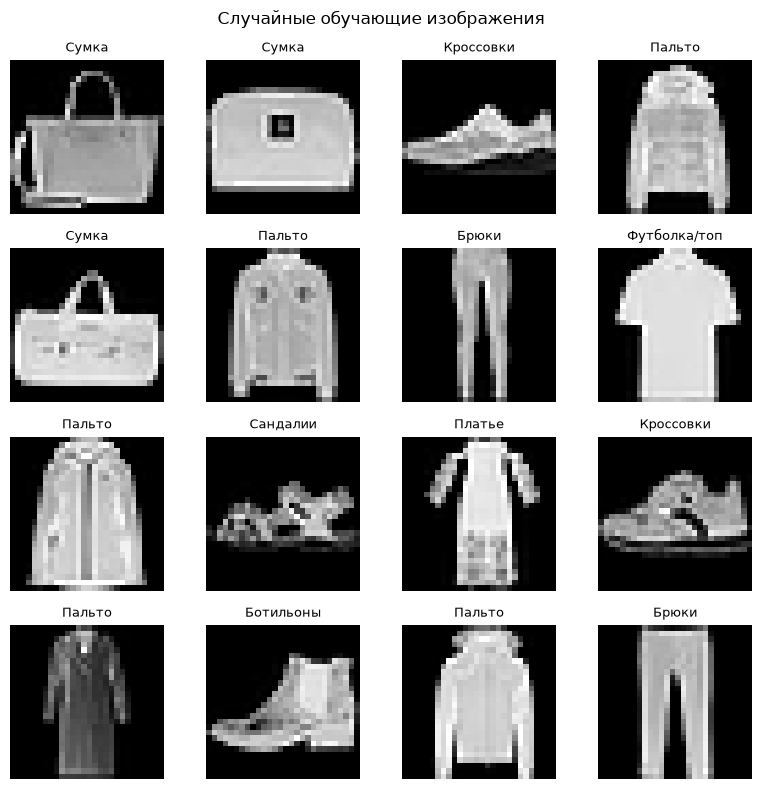

In [6]:
random_indices = np.random.choice(len(full_train_data), 16, replace=False)

plt.figure(figsize=(8, 8))
for i, idx in enumerate(random_indices):
    image, label = full_train_data[idx]
    plt.subplot(4, 4, i + 1)
    plt.imshow(image.squeeze() * 0.5 + 0.5, cmap="gray")
    plt.title(class_names[label], fontsize=9)
    plt.axis("off")
plt.suptitle("Случайные обучающие изображения")
plt.tight_layout()
plt.show()

In [7]:
# Проверка сбалансированности классов
label_counts = pd.Series(full_train_data.targets.numpy()).value_counts().sort_index()
label_counts.index = class_names
print(label_counts)

Футболка/топ    6000
Брюки           6000
Пуловер         6000
Платье          6000
Пальто          6000
Сандалии        6000
Рубашка         6000
Кроссовки       6000
Сумка           6000
Ботильоны       6000
Name: count, dtype: int64


## 5. Подготовка данных


In [8]:
generator = torch.Generator().manual_seed(SEED)
train_data, val_data = random_split(full_train_data, [50000, 10000], generator=generator)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

print("Обучение:", len(train_data))
print("Валидация:", len(val_data))
print("Тест:", len(test_data))
print("Пакетов в эпохе:", len(train_loader))

Обучение: 50000
Валидация: 10000
Тест: 10000
Пакетов в эпохе: 782


In [9]:
images, labels = next(iter(train_loader))
print("Пакет изображений:", images.shape)
print("Пакет меток:", labels.shape)

Пакет изображений: torch.Size([64, 1, 28, 28])
Пакет меток: torch.Size([64])


## 6. Полносвязная нейронная сеть


In [10]:
class FCNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.layers(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


fc_model = FCNet().to(device)
print(fc_model)
print("Обучаемых параметров:", count_parameters(fc_model))

FCNet(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Обучаемых параметров: 235146


In [11]:
# Проверка размера выхода
test_out = fc_model(images.to(device))
print("Размер выхода:", test_out.shape)

Размер выхода: torch.Size([64, 10])


## 7. Обучение полносвязной сети


In [12]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            total_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, epochs):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)            # Прямой проход
            loss = loss_fn(outputs, labels)    # Вычисление ошибки предсказаний

            optimizer.zero_grad()              # Сброс старых градиентов
            loss.backward()                    # Обратное распространение ошибки
            optimizer.step()                   # Обновление весов

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Эпоха {epoch + 1}/{epochs}")
        print(f"Обучающий loss: {train_loss:.4f}")
        print(f"Обучающая точность: {train_acc * 100:.2f}%")
        print(f"Валидационный loss: {val_loss:.4f}")
        print(f"Валидационная точность: {val_acc * 100:.2f}%")
        print("-" * 30)

    return history

In [13]:
torch.manual_seed(SEED)
fc_model = FCNet().to(device)   # Новая модель, чтобы проверка размера выхода не влияла на обучение
fc_history = train_model(fc_model, train_loader, val_loader, EPOCHS)

Эпоха 1/10
Обучающий loss: 0.5151
Обучающая точность: 81.19%
Валидационный loss: 0.4085
Валидационная точность: 85.00%
------------------------------
Эпоха 2/10
Обучающий loss: 0.3763
Обучающая точность: 86.08%
Валидационный loss: 0.3656
Валидационная точность: 86.59%
------------------------------
Эпоха 3/10
Обучающий loss: 0.3386
Обучающая точность: 87.52%
Валидационный loss: 0.3592
Валидационная точность: 87.11%
------------------------------
Эпоха 4/10
Обучающий loss: 0.3142
Обучающая точность: 88.42%
Валидационный loss: 0.3246
Валидационная точность: 88.06%
------------------------------
Эпоха 5/10
Обучающий loss: 0.2894
Обучающая точность: 89.21%
Валидационный loss: 0.3286
Валидационная точность: 88.06%
------------------------------
Эпоха 6/10
Обучающий loss: 0.2737
Обучающая точность: 89.71%
Валидационный loss: 0.3158
Валидационная точность: 88.65%
------------------------------
Эпоха 7/10
Обучающий loss: 0.2597
Обучающая точность: 90.19%
Валидационный loss: 0.3337
Валидационна

## 8. Графики обучения полносвязной сети


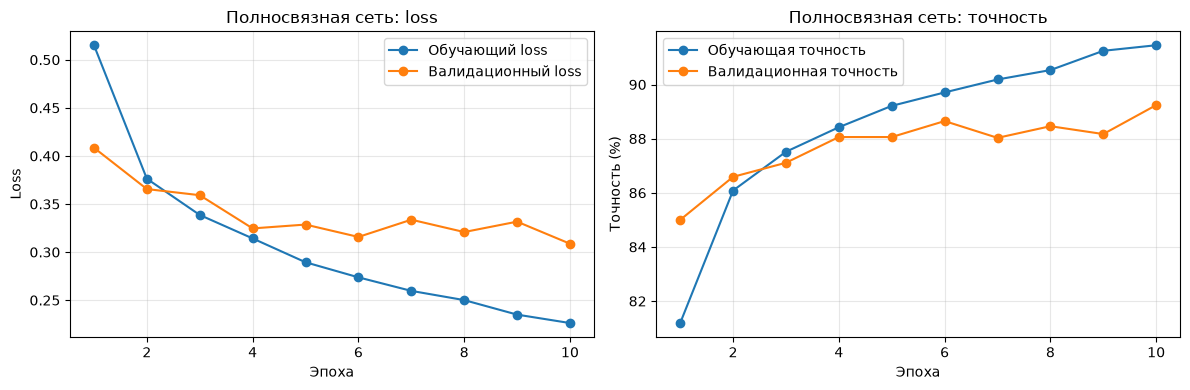

In [14]:
def plot_history(history, title):
    epochs_range = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history["train_loss"], marker="o", label="Обучающий loss")
    plt.plot(epochs_range, history["val_loss"], marker="o", label="Валидационный loss")
    plt.xlabel("Эпоха")
    plt.ylabel("Loss")
    plt.title(f"{title}: loss")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, [a * 100 for a in history["train_acc"]], marker="o", label="Обучающая точность")
    plt.plot(epochs_range, [a * 100 for a in history["val_acc"]], marker="o", label="Валидационная точность")
    plt.xlabel("Эпоха")
    plt.ylabel("Точность (%)")
    plt.title(f"{title}: точность")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_history(fc_history, "Полносвязная сеть")

## 9. Проверка полносвязной сети на тестовых данных


In [15]:
loss_fn = nn.CrossEntropyLoss()
fc_test_loss, fc_test_acc = evaluate(fc_model, test_loader, loss_fn)

print(f"Тестовый loss FC: {fc_test_loss:.4f}")
print(f"Тестовая точность FC: {fc_test_acc * 100:.2f}%")

Тестовый loss FC: 0.3404
Тестовая точность FC: 88.78%


## 10. Свёрточная нейронная сеть


In [16]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_layers(x)


cnn_model = CNN().to(device)
print(cnn_model)
print("Обучаемых параметров:", count_parameters(cnn_model))

CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Обучаемых параметров: 421642


In [17]:
# Проверка размеров после каждого слоя и значения 64*7*7
x = images[:1].to(device)
print("Вход:", x.shape)
for layer in cnn_model.conv_layers:
    x = layer(x)
    print(layer.__class__.__name__, "->", x.shape)
print("Итоговый выход:", cnn_model(images.to(device)).shape)

Вход: torch.Size([1, 1, 28, 28])
Conv2d -> torch.Size([1, 32, 28, 28])
ReLU -> torch.Size([1, 32, 28, 28])
MaxPool2d -> torch.Size([1, 32, 14, 14])
Conv2d -> torch.Size([1, 64, 14, 14])
ReLU -> torch.Size([1, 64, 14, 14])
MaxPool2d -> torch.Size([1, 64, 7, 7])
Итоговый выход: torch.Size([64, 10])


## 11. Обучение CNN


In [18]:
torch.manual_seed(SEED)
cnn_model = CNN().to(device)
cnn_history = train_model(cnn_model, train_loader, val_loader, EPOCHS)

Эпоха 1/10
Обучающий loss: 0.4553
Обучающая точность: 83.38%
Валидационный loss: 0.3553
Валидационная точность: 87.24%
------------------------------
Эпоха 2/10
Обучающий loss: 0.2927
Обучающая точность: 89.35%
Валидационный loss: 0.2734
Валидационная точность: 90.02%
------------------------------
Эпоха 3/10
Обучающий loss: 0.2431
Обучающая точность: 91.11%
Валидационный loss: 0.2625
Валидационная точность: 90.17%
------------------------------
Эпоха 4/10
Обучающий loss: 0.2116
Обучающая точность: 92.29%
Валидационный loss: 0.2449
Валидационная точность: 91.11%
------------------------------
Эпоха 5/10
Обучающий loss: 0.1850
Обучающая точность: 93.14%
Валидационный loss: 0.2317
Валидационная точность: 91.68%
------------------------------
Эпоха 6/10
Обучающий loss: 0.1618
Обучающая точность: 94.08%
Валидационный loss: 0.2191
Валидационная точность: 92.08%
------------------------------
Эпоха 7/10
Обучающий loss: 0.1398
Обучающая точность: 94.85%
Валидационный loss: 0.2282
Валидационна

## 12. Графики обучения CNN


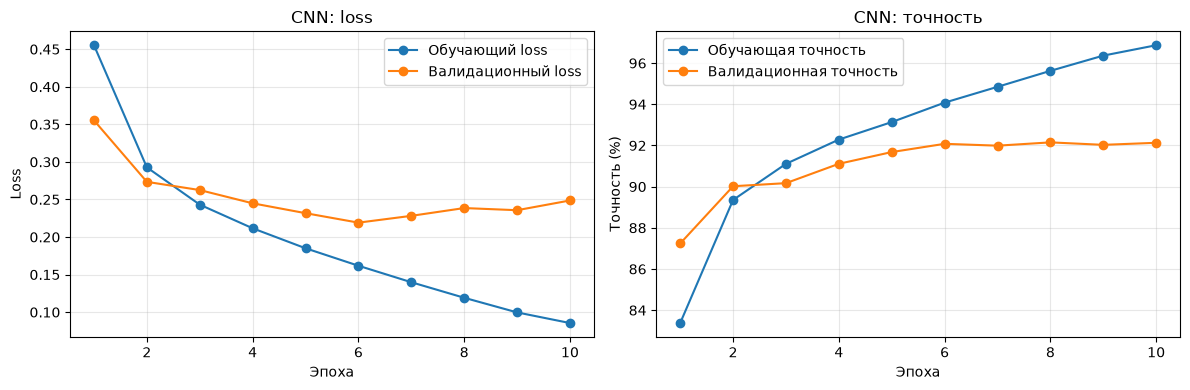

In [19]:
plot_history(cnn_history, "CNN")

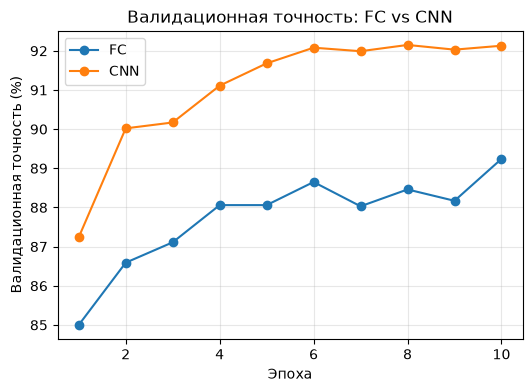

In [20]:
# Сравнение валидационной точности двух моделей
epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs_range, [a * 100 for a in fc_history["val_acc"]], marker="o", label="FC")
plt.plot(epochs_range, [a * 100 for a in cnn_history["val_acc"]], marker="o", label="CNN")
plt.xlabel("Эпоха")
plt.ylabel("Валидационная точность (%)")
plt.title("Валидационная точность: FC vs CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 13. Проверка CNN


In [21]:
cnn_test_loss, cnn_test_acc = evaluate(cnn_model, test_loader, loss_fn)

print(f"Тестовый loss CNN: {cnn_test_loss:.4f}")
print(f"Тестовая точность CNN: {cnn_test_acc * 100:.2f}%")
print()
print(f"Тестовая точность FC:  {fc_test_acc * 100:.2f}%")
print(f"Тестовая точность CNN: {cnn_test_acc * 100:.2f}%")

Тестовый loss CNN: 0.2744
Тестовая точность CNN: 91.69%

Тестовая точность FC:  88.78%
Тестовая точность CNN: 91.69%


## 14. Визуализация предсказаний


In [22]:
if cnn_test_acc >= fc_test_acc:
    best_model, best_name = cnn_model, "CNN"
else:
    best_model, best_name = fc_model, "Полносвязная"
print("Лучшая модель на тестовой выборке:", best_name)


def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            all_preds.append(outputs.argmax(dim=1).cpu())
            all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()


best_preds, test_labels = get_predictions(best_model, test_loader)
print("Количество тестовых предсказаний:", len(best_preds))

Лучшая модель на тестовой выборке: CNN
Количество тестовых предсказаний: 10000


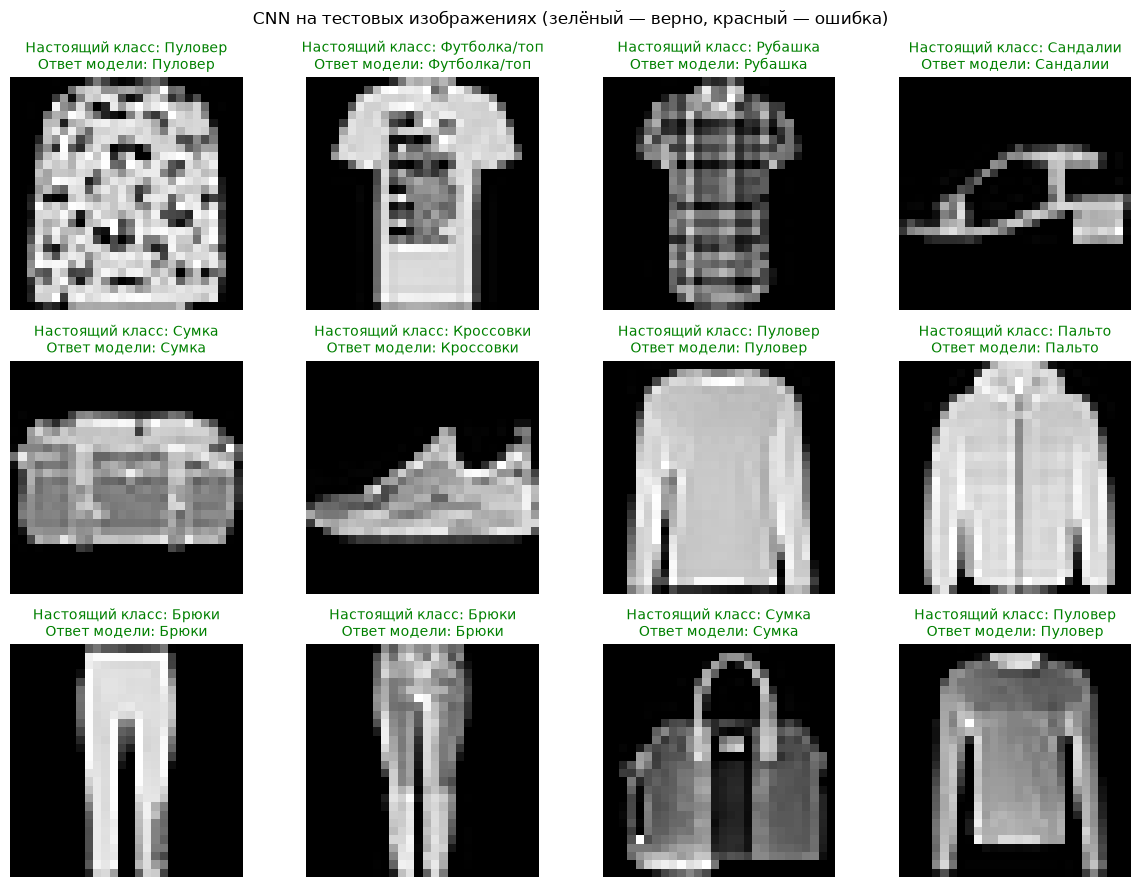

In [23]:
sample_indices = np.random.choice(len(test_data), 12, replace=False)

plt.figure(figsize=(12, 9))
for i, idx in enumerate(sample_indices):
    image, _ = test_data[idx]
    true_label = test_labels[idx]
    pred_label = best_preds[idx]
    color = "green" if true_label == pred_label else "red"

    plt.subplot(3, 4, i + 1)
    plt.imshow(image.squeeze() * 0.5 + 0.5, cmap="gray")
    plt.title(f"Настоящий класс: {class_names[true_label]}\nОтвет модели: {class_names[pred_label]}", color=color, fontsize=10)
    plt.axis("off")
plt.suptitle(f"{best_name} на тестовых изображениях (зелёный — верно, красный — ошибка)")
plt.tight_layout()
plt.show()

## 15. Анализ ошибочных предсказаний


Количество ошибок: 831 из 10000


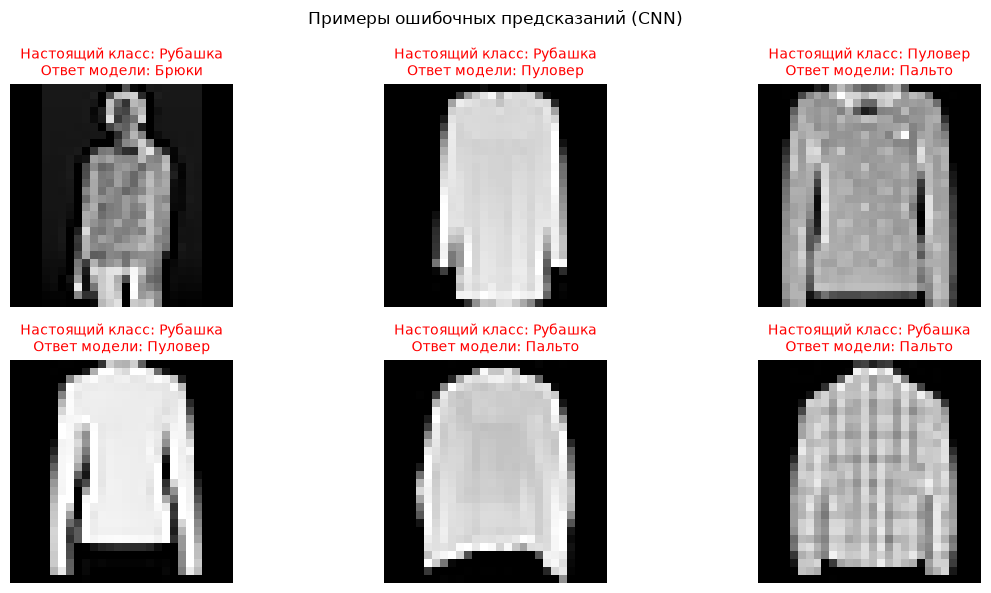

In [24]:
wrong_indices = np.where(best_preds != test_labels)[0]
print("Количество ошибок:", len(wrong_indices), "из", len(test_labels))

shown_wrong = np.random.choice(wrong_indices, 6, replace=False)

plt.figure(figsize=(12, 6))
for i, idx in enumerate(shown_wrong):
    image, _ = test_data[idx]
    plt.subplot(2, 3, i + 1)
    plt.imshow(image.squeeze() * 0.5 + 0.5, cmap="gray")
    plt.title(f"Настоящий класс: {class_names[test_labels[idx]]}\nОтвет модели: {class_names[best_preds[idx]]}", color="red", fontsize=10)
    plt.axis("off")
plt.suptitle(f"Примеры ошибочных предсказаний ({best_name})")
plt.tight_layout()
plt.show()

In [25]:
# Самые частые пары ошибочных классов
mistakes = pd.DataFrame({
    "Настоящий класс": [class_names[i] for i in test_labels[wrong_indices]],
    "Ответ модели": [class_names[i] for i in best_preds[wrong_indices]]
})
mistakes.value_counts().head(8)

Настоящий класс  Ответ модели
Рубашка          Футболка/топ    140
                 Пальто          101
                 Пуловер          61
Футболка/топ     Рубашка          53
Пальто           Пуловер          51
Пуловер          Рубашка          38
                 Пальто           37
Ботильоны        Кроссовки        37
Name: count, dtype: int64

## 16. Матрица ошибок


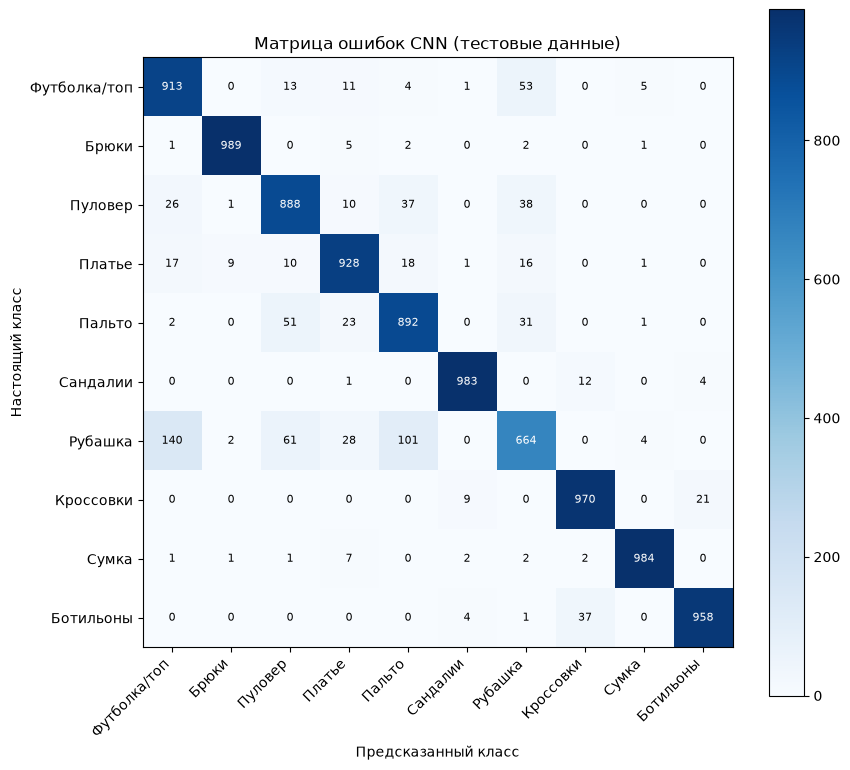

In [26]:
cnn_preds, cnn_labels = get_predictions(cnn_model, test_loader)

conf_matrix = np.zeros((10, 10), dtype=int)
for t, p in zip(cnn_labels, cnn_preds):
    conf_matrix[t, p] += 1

plt.figure(figsize=(9, 8))
plt.imshow(conf_matrix, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")
plt.title("Матрица ошибок CNN (тестовые данные)")

for i in range(10):
    for j in range(10):
        value = conf_matrix[i, j]
        plt.text(j, i, value, ha="center", va="center",
                 color="white" if value > conf_matrix.max() / 2 else "black", fontsize=8)

plt.tight_layout()
plt.show()

In [27]:
# Точность отдельно для каждого класса
per_class_acc = conf_matrix.diagonal() / conf_matrix.sum(axis=1)
pd.DataFrame({"Класс": class_names, "Точность CNN (%)": (per_class_acc * 100).round(2)}).sort_values("Точность CNN (%)")

,Класс,Точность CNN (%)
6,Рубашка,66.4
2,Пуловер,88.8
4,Пальто,89.2
0,Футболка/топ,91.3
3,Платье,92.8
9,Ботильоны,95.8
7,Кроссовки,97.0
5,Сандалии,98.3
8,Сумка,98.4
1,Брюки,98.9


## 17. Сравнение полносвязной сети и CNN


In [28]:
comparison = pd.DataFrame({
    "Модель": ["Полносвязная", "CNN"],
    "Обучаемые параметры": [count_parameters(fc_model), count_parameters(cnn_model)],
    "Тестовая точность (%)": [round(fc_test_acc * 100, 2), round(cnn_test_acc * 100, 2)]
})
comparison

,Модель,Обучаемые параметры,Тестовая точность (%)
0,Полносвязная,235146,88.78
1,CNN,421642,91.69


In [29]:
difference = (cnn_test_acc - fc_test_acc) * 100
if difference > 0:
    print(f"В этом запуске CNN лучше на {difference:.2f} процентного пункта.")
elif difference < 0:
    print(f"В этом запуске полносвязная сеть лучше на {-difference:.2f} процентного пункта.")
else:
    print("В этом запуске модели показали одинаковую тестовую точность.")

В этом запуске CNN лучше на 2.91 процентного пункта.
